# 01 · Data exploration

This notebook looks at the data behind the predictor: where it comes from, how complete it is and which football
patterns the model can learn from.

All loading and cleaning lives in the `football_predictor` package (`src/football_predictor/`), so this notebook only
*uses* it. Run `football-predictor data` once first (or let the first cell download everything; ~3 minutes).

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

# Colours shared with the website (validated for colour-vision deficiency)
HOME, DRAW, AWAY = "#2a78d6", "#1baf7a", "#eb6834"
GRID, INK, MUTED = "#e2e0da", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})

In [2]:
from football_predictor.config import COMPETITIONS_BY_CODE
from football_predictor.dataset import build_matches

matches = build_matches(refresh=False, save=False)
matches["league"] = matches["competition"].map(lambda c: f"{COMPETITIONS_BY_CODE[c].name} ({COMPETITIONS_BY_CODE[c].country})")
print(f"{len(matches):,} matches · {matches['date'].min():%d %b %Y} to {matches['date'].max():%d %b %Y}")
matches.tail(3)

89,282 matches · 28 Mar 2014 to 23 Nov 2026


,match_id,date,season,competition,home_team,away_team,home_goals,away_goals,result,home_xg,away_xg,home_shots,away_shots,home_sot,away_sot,home_corners,away_corners,home_fouls,away_fouls,home_yellow,away_yellow,home_red,away_red,odds_home,odds_draw,odds_away,neutral,status,source,league
89279,20261123-hammarby-goteborg,2026-11-23,2026,SWE,Hammarby,Goteborg,3.0,1.0,H,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.13,7.91,13.88,False,played,football-data,Allsvenskan (Sweden)
89280,20261123-orgryte-kalmar,2026-11-23,2026,SWE,Orgryte,Kalmar,3.0,2.0,H,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.30,3.57,1.98,False,played,football-data,Allsvenskan (Sweden)
89281,20261123-buyuksehyr-corum,2026-11-23,2026,T1,Buyuksehyr,Corum,4.0,2.0,H,1.83,1.33,26.0,11.0,5.0,3.0,3.0,1.0,7.0,6.0,0.0,3.0,0.0,0.0,1.85,3.69,3.58,False,played,football-data,Süper Lig (Turkey)


## 1. Sources and coverage

| Source | What it gives | Used for |
|---|---|---|
| football-data.co.uk (`/mmz4281`) | 16 main divisions, one CSV per season: results, shots, corners, cards, odds, xG from 2026/27 | training data, odds |
| football-data.co.uk (`/new`) | Austria, Switzerland, Denmark, Norway, Sweden: results + closing odds | training data (ratings for European clubs) |
| ESPN public API | Champions, Europa and Conference League since 2014; every fixture, kick-off, live score and DraftKings odds | European matches, fixtures, settlement |

The original version scraped xG from **Understat**. Understat now blocks scripted requests (and never covered the
Champions League), which is why European matches never made it into the old model.

In [3]:
coverage = (
    matches.groupby(["league", "season"]).size().unstack("season").fillna(0).astype(int)
)
coverage.iloc[:, -6:]

season,2021,2022,2023,2024,2025,2026
league,,,,,,
2. Bundesliga (Germany),306,306,306,306,306,108
Allsvenskan (Sweden),242,242,240,242,240,232
Bundesliga (Austria),195,195,195,192,192,78
Bundesliga (Germany),306,306,306,306,306,90
Champions League (Europe),125,125,125,189,189,72
Championship (England),552,552,552,552,552,192
Conference League (Europe),141,141,141,153,153,54
Eliteserien (Norway),241,242,242,242,240,216
Eredivisie (Netherlands),306,306,306,306,306,117


In [4]:
stats_cols = ["home_shots", "home_sot", "home_corners", "home_xg", "odds_home"]
availability = matches.assign(kind=matches["competition"].map(lambda c: COMPETITIONS_BY_CODE[c].kind))
(availability.groupby("kind")[stats_cols].apply(lambda d: d.notna().mean()) * 100).round(1)

,home_shots,home_sot,home_corners,home_xg,odds_home
kind,,,,,
cup,0.0,0.0,0.0,0.0,0.0
league,72.3,72.3,72.3,2.2,99.9


Shots/corners exist for the main divisions only, xG only for the current season, and bookmaker odds for every
domestic match but not for historical European games. XGBoost handles missing values natively, learning a default
direction at every split, so these gaps are not imputed with fake zeros (the old notebook filled them with `0` and
dropped every Champions League match with an odds filter).

## 2. Outcomes: home advantage is real, but shrinking

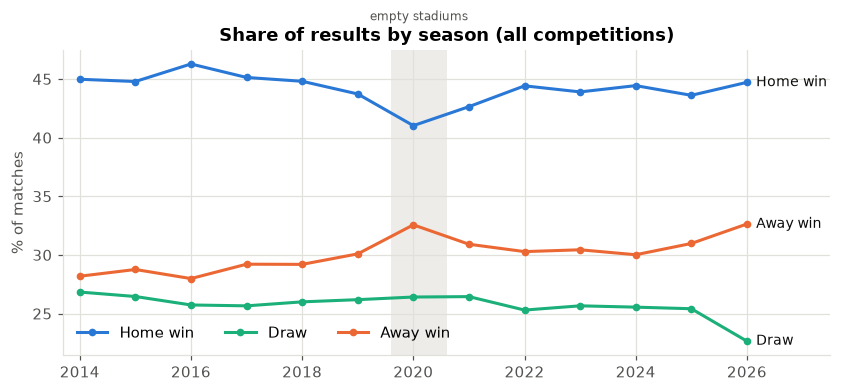

In [5]:
res = matches[matches["status"] == "played"]
by_season = res.groupby("season")["result"].value_counts(normalize=True).unstack()[["H", "D", "A"]]

fig, ax = plt.subplots(figsize=(9, 3.6))
for col, color, label in [("H", HOME, "Home win"), ("D", DRAW, "Draw"), ("A", AWAY, "Away win")]:
    ax.plot(by_season.index, by_season[col] * 100, color=color, lw=2, marker="o", ms=4, label=label)
    ax.annotate(label, (by_season.index[-1], by_season[col].iloc[-1] * 100), xytext=(6, 0),
                textcoords="offset points", va="center", color=INK, fontsize=9)
ax.axvspan(2019.6, 2020.6, color=GRID, alpha=0.6, lw=0)
ax.text(2020.1, 50, "empty stadiums", ha="center", color=MUTED, fontsize=8)
ax.set_ylabel("% of matches")
ax.set_title("Share of results by season (all competitions)")
ax.set_xlim(by_season.index.min() - 0.3, by_season.index.max() + 1.5)
ax.legend(frameon=False, loc="lower left", ncol=3)
plt.show()

Home teams won about 45% of matches before 2020, fell to 41% in the empty-stadium 2020/21 season and have
settled around 44% since. The game changes over time, which is why the model weights recent seasons more heavily
(4-year half-life).

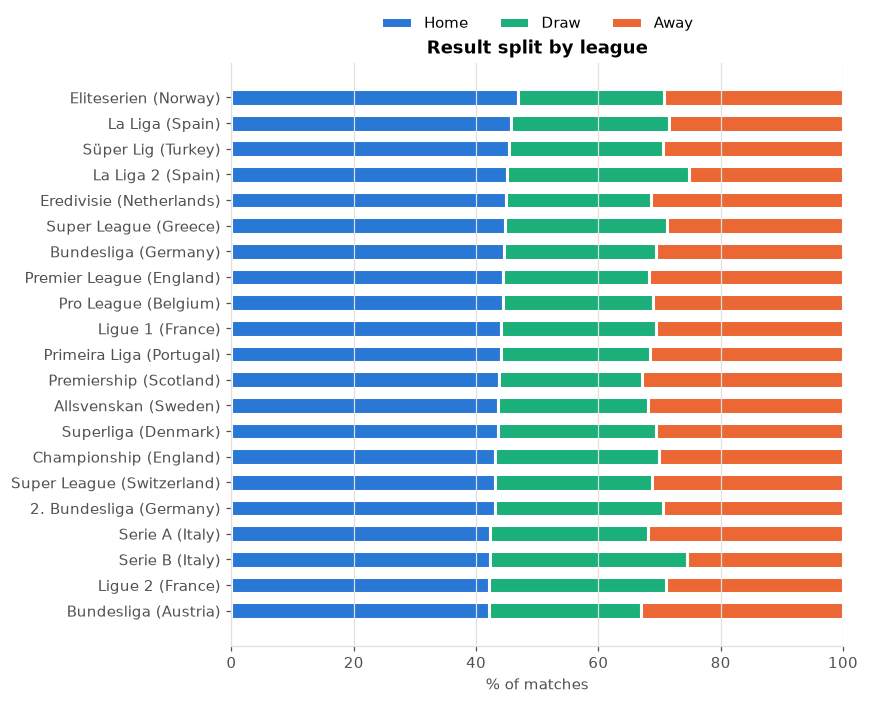

In [6]:
league_rates = (
    res[res["competition"].map(lambda c: COMPETITIONS_BY_CODE[c].kind == "league")]
    .groupby("league")["result"].value_counts(normalize=True).unstack()[["H", "D", "A"]]
    .sort_values("H")
)
fig, ax = plt.subplots(figsize=(8, 6.5))
left = np.zeros(len(league_rates))
for col, color, label in [("H", HOME, "Home"), ("D", DRAW, "Draw"), ("A", AWAY, "Away")]:
    ax.barh(league_rates.index, league_rates[col] * 100, left=left, color=color, height=0.65,
            label=label, edgecolor="white", linewidth=2)
    left += league_rates[col].to_numpy() * 100
ax.set_xlim(0, 100)
ax.set_xlabel("% of matches")
ax.set_title("Result split by league")
ax.legend(frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.03))
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 3. Goals look Poisson, which justifies the score model

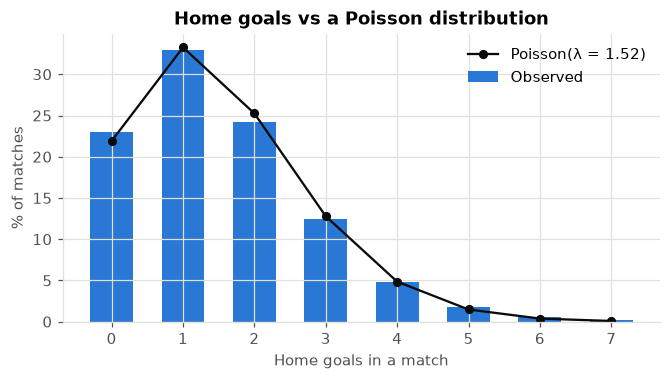

In [7]:
from scipy.stats import poisson

goals = res["home_goals"].astype(int).clip(upper=7)
lam = res["home_goals"].mean()
observed = goals.value_counts(normalize=True).sort_index()
expected = poisson.pmf(observed.index, lam)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(observed.index, observed * 100, width=0.6, color=HOME, label="Observed")
ax.plot(observed.index, expected * 100, color=INK, marker="o", lw=1.5, ms=5, label=f"Poisson(λ = {lam:.2f})")
ax.set_xlabel("Home goals in a match")
ax.set_ylabel("% of matches")
ax.set_title("Home goals vs a Poisson distribution")
ax.legend(frameon=False)
plt.show()

The fit is close. Treating the two teams' goals as independent Poisson variables is known to slightly
under-estimate low-scoring draws (Dixon & Coles, 1997), so the final 1X2 blends the Poisson-derived probabilities with
a direct classifier.

## 4. Ratings sanity check

In [8]:
from football_predictor.features import elo_ratings

ordered = matches.sort_values("date", kind="stable").reset_index(drop=True)
_, ratings = elo_ratings(ordered)
last_seen = pd.concat([ordered[["date", "home_team"]].rename(columns={"home_team": "team"}),
                       ordered[["date", "away_team"]].rename(columns={"away_team": "team"})]).groupby("team")["date"].max()
active = last_seen[last_seen > ordered["date"].max() - pd.Timedelta(days=120)].index
top = pd.Series(ratings)[active].sort_values(ascending=False).head(15).round(0)
top.to_frame("Elo")

,Elo
Bayern Munich,2050.0
Arsenal,2048.0
Paris SG,2022.0
Barcelona,2013.0
Real Madrid,1983.0
Inter,1934.0
Man City,1931.0
Liverpool,1891.0
Dortmund,1883.0
Benfica,1875.0


The top of the table is largely what one would expect, and it mixes leagues: because league and European
matches share one rating scale, a club from a smaller league that beats big teams in Europe earns a rating comparable
to theirs.

## 5. The bookmakers are well calibrated: the benchmark to beat

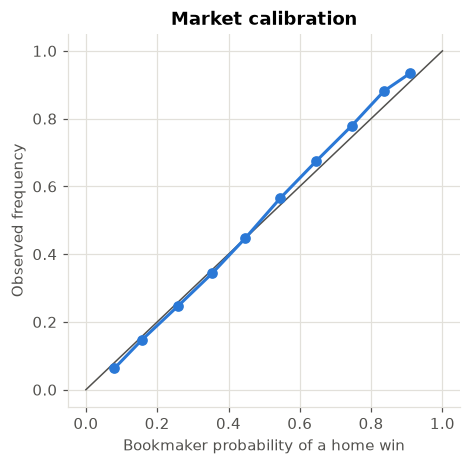

,predicted,observed,n
mkt_p_home,,,
"(0.0, 0.1]",0.080,0.063,903
"(0.1, 0.2]",0.156,0.146,4630
"(0.2, 0.3]",0.257,0.246,9699
"(0.3, 0.4]",0.354,0.343,19697
"(0.4, 0.5]",0.447,0.447,21727
"(0.5, 0.6]",0.545,0.566,13244
"(0.6, 0.7]",0.646,0.674,6852
"(0.7, 0.8]",0.746,0.779,3858
"(0.8, 0.9]",0.836,0.882,1519


In [9]:
from football_predictor.features import market_probabilities

mk = pd.concat([res, market_probabilities(res)], axis=1).dropna(subset=["mkt_p_home"])
bins = pd.cut(mk["mkt_p_home"], np.linspace(0, 1, 11))
calib = mk.assign(home_win=mk["result"].eq("H")).groupby(bins, observed=True).agg(
    predicted=("mkt_p_home", "mean"), observed=("home_win", "mean"), n=("home_win", "size"))

fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.plot([0, 1], [0, 1], color=MUTED, lw=1)
ax.plot(calib["predicted"], calib["observed"], color=HOME, lw=2, marker="o", ms=6)
ax.set_xlabel("Bookmaker probability of a home win")
ax.set_ylabel("Observed frequency")
ax.set_title("Market calibration")
plt.show()
calib.round(3)

Margin-free bookmaker probabilities sit close to the diagonal, with the classic *favourite–longshot bias*: strong
favourites win slightly more often than their price implies (e.g. 0.84 priced, 0.88 observed). Any model is judged
against this benchmark: matching it is already good, beating it consistently is very hard. See `02_modelling.ipynb`.